In [ ]:
from google.colab import files

# Prompt user to upload files
uploaded = files.upload()

# Print the names and sizes of the uploaded files
for filename, content in uploaded.items():
    print(f'Uploaded file "{filename}" with length {len(content)} bytes')

Saving starbucks.csv to starbucks (1).csv
Uploaded file "starbucks (1).csv" with length 26898 bytes


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('starbucks.csv')

# Display basic information
print("--- Data Info ---")
display(df.info())

print("\n--- First 5 Rows ---")
display(df.head())

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242 entries, 0 to 241
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Beverage_category          242 non-null    object 
 1   Beverage                   242 non-null    object 
 2   Beverage_prep              242 non-null    object 
 3   Calories                   242 non-null    int64  
 4    Total Fat (g)             242 non-null    object 
 5   Trans Fat (g)              242 non-null    float64
 6   Saturated Fat (g)          242 non-null    float64
 7    Sodium (mg)               242 non-null    int64  
 8    Total Carbohydrates (g)   242 non-null    int64  
 9   Cholesterol (mg)           242 non-null    int64  
 10   Dietary Fibre (g)         242 non-null    int64  
 11   Sugars (g)                242 non-null    int64  
 12   Protein (g)               242 non-null    float64
 13  Vitamin A (% DV)           242 n

None


--- First 5 Rows ---


,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75


In [ ]:
# Clean column names (strip whitespaces)
df.columns = df.columns.str.strip()

# Convert numeric columns that might have been parsed as strings due to spacing or special characters
# Inspect columns to find numerical ones
numeric_cols = ['Calories', 'Total Fat (g)', 'Trans Fat (g)', 'Saturated Fat (g)',
                'Sodium (mg)', 'Total Carbohydrates (g)', 'Cholesterol (mg)',
                'Dietary Fibre (g)', 'Sugars (g)', 'Protein (g)']

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Check for missing values
print("--- Missing Values ---")
display(df.isnull().sum())

--- Missing Values ---


,0
Beverage_category,0
Beverage,0
Beverage_prep,0
Calories,0
Total Fat (g),1
Trans Fat (g),0
Saturated Fat (g),0
Sodium (mg),0
Total Carbohydrates (g),0
Cholesterol (mg),0


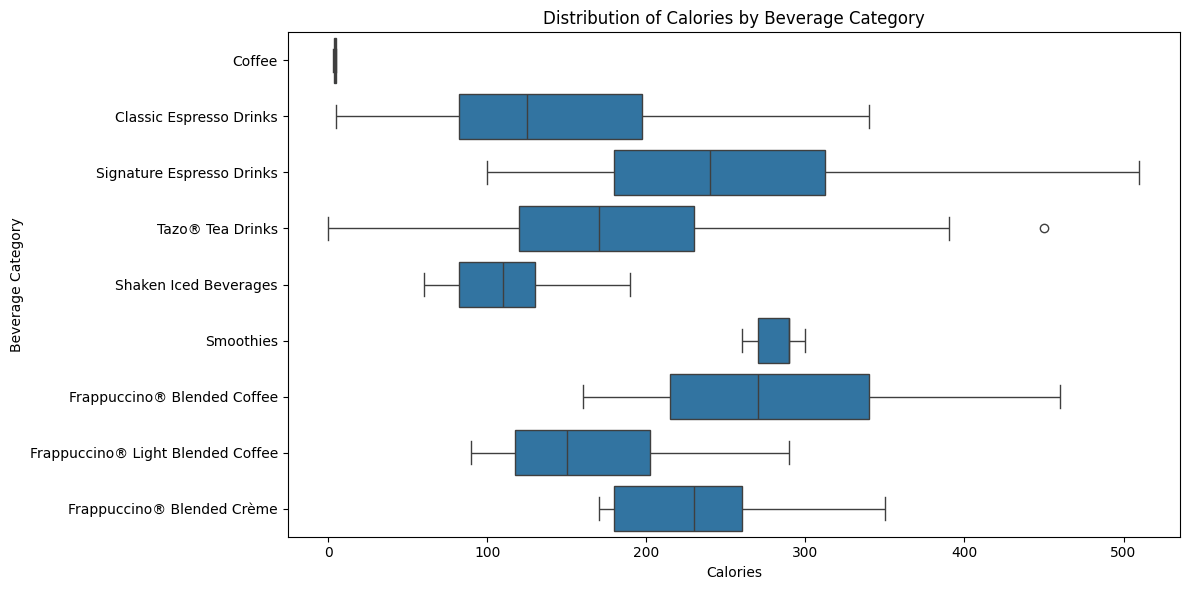

In [ ]:
# EDA: Distribution of Calories across Beverage Categories
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Calories', y='Beverage_category')
plt.title('Distribution of Calories by Beverage Category')
plt.xlabel('Calories')
plt.ylabel('Beverage Category')
plt.tight_layout()
plt.show()

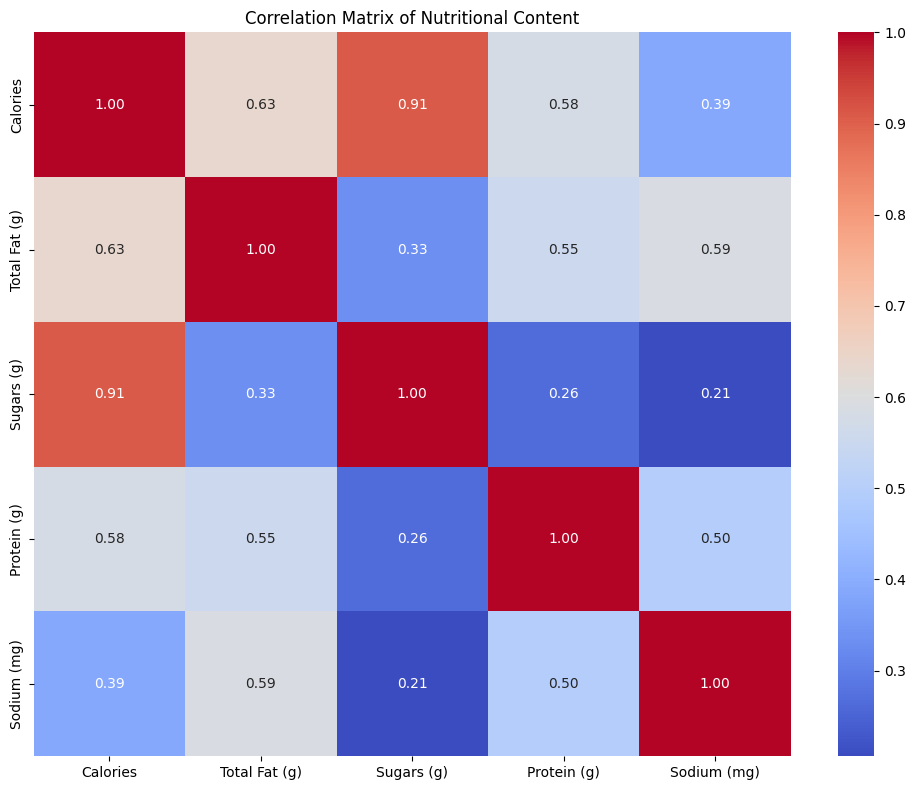

In [ ]:
# EDA: Correlation between major nutritional values
plt.figure(figsize=(10, 8))
corr_cols = [c for c in ['Calories', 'Total Fat (g)', 'Sugars (g)', 'Protein (g)', 'Sodium (mg)'] if c in df.columns]
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Nutritional Content')
plt.tight_layout()
plt.show()

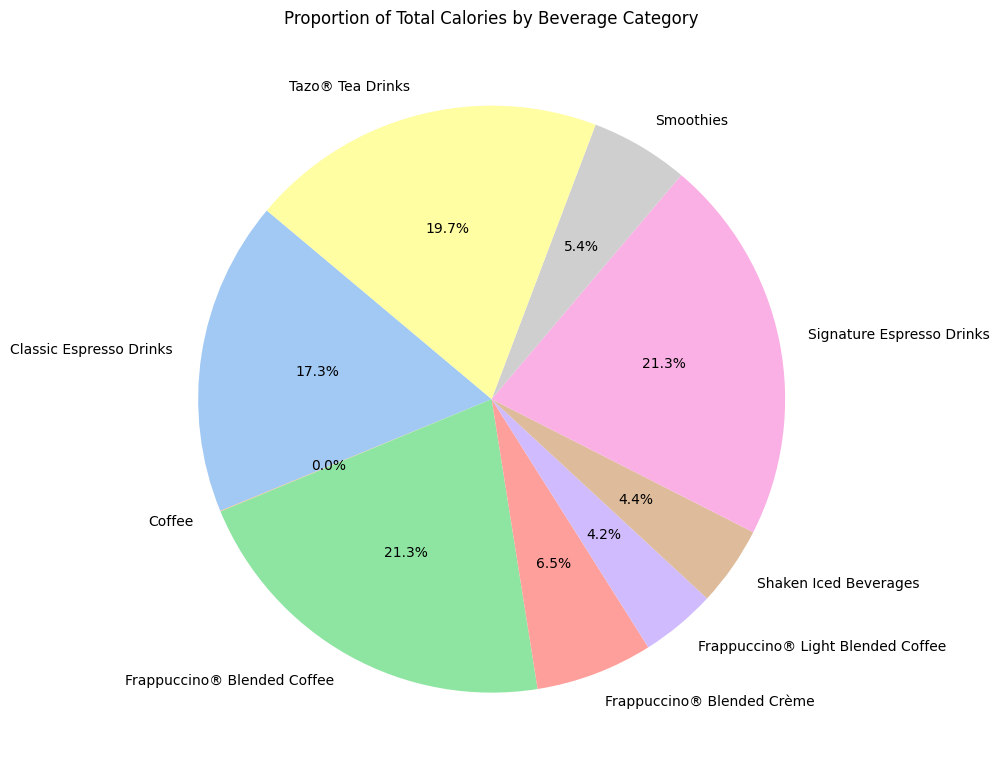

In [ ]:
# 1. Draw a pie chart of Calories distributed by Beverage Category
category_calories = df.groupby('Beverage_category')['Calories'].sum()

plt.figure(figsize=(10, 10))
plt.pie(category_calories, labels=category_calories.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Proportion of Total Calories by Beverage Category')
plt.tight_layout()
plt.show()

In [ ]:
# 2. Identify the drink with the highest calories
highest_calorie_row = df.loc[df['Calories'].idxmax()]
print(f"The drink with the highest calories is:\n")
print(f"Category: {highest_calorie_row['Beverage_category']}")
print(f"Beverage: {highest_calorie_row['Beverage']}")
print(f"Preparation: {highest_calorie_row['Beverage_prep']}")
print(f"Calories: {highest_calorie_row['Calories']}")

The drink with the highest calories is:

Category: Signature Espresso Drinks
Beverage: White Chocolate Mocha (Without Whipped Cream)
Preparation: 2% Milk
Calories: 510


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import numpy as np

# Let's clean up any missing values in our features first
features = ['Total Fat (g)', 'Trans Fat (g)', 'Saturated Fat (g)', 'Sodium (mg)',
            'Total Carbohydrates (g)', 'Cholesterol (mg)', 'Dietary Fibre (g)',
            'Sugars (g)', 'Protein (g)']

# Fill any NaN values with the median of that column
for col in features:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Define a classification target: High Calorie (above median calorie content)
median_calories = df['Calories'].median()
df['High_Calorie'] = (df['Calories'] > median_calories).astype(int)

X = df[features]
y = df['High_Calorie']

# Split data: 70% Train, 30% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)

# Split Temporary data into 20% Test and 10% Validation relative to the overall dataset
# Since 30% remains, we split it as 2/3 (which is 20% of total) and 1/3 (which is 10% of total)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=1/3, random_state=42)

print(f"Training set size: {len(X_train)} (70%)")
print(f"Testing set size: {len(X_test)} (20%)")
print(f"Validation set size: {len(X_val)} (10%)")

Training set size: 169 (70%)
Testing set size: 48 (20%)
Validation set size: 25 (10%)


In [ ]:
# Train the Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=42, max_depth=4)
clf.fit(X_train, y_train)

# Evaluate model accuracy
y_val_pred = clf.predict(X_val)
y_test_pred = clf.predict(X_test)

val_accuracy = accuracy_score(y_val, y_val_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Decision Tree Validation Accuracy: {val_accuracy:.2%}")
print(f"Decision Tree Test Accuracy: {test_accuracy:.2%}")

Decision Tree Validation Accuracy: 88.00%
Decision Tree Test Accuracy: 91.67%


/tmp/ipykernel_1225/2119010132.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=accuracies, palette='viridis')


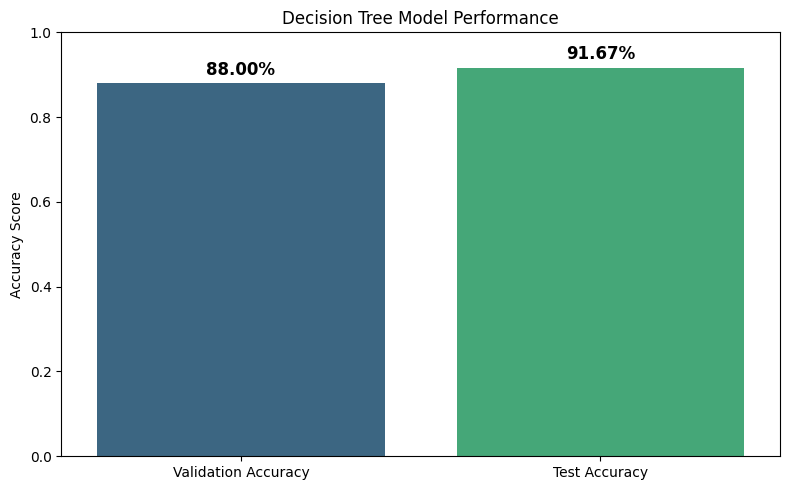

In [ ]:
# Plot the accuracies
plt.figure(figsize=(8, 5))
metrics = ['Validation Accuracy', 'Test Accuracy']
accuracies = [val_accuracy, test_accuracy]

sns.barplot(x=metrics, y=accuracies, palette='viridis')
plt.ylim(0, 1.0)
plt.ylabel('Accuracy Score')
plt.title('Decision Tree Model Performance')

# Add the accuracy values on top of the bars
for i, acc in enumerate(accuracies):
    plt.text(i, acc + 0.02, f"{acc:.2%}", ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Select 10 random drinks from the dataset
sample_df = df.sample(n=10, random_state=42)

# Extract the features for prediction
X_sample = sample_df[features]

# Generate predictions
sample_df['Predicted_High_Calorie'] = clf.predict(X_sample)

# Create a mapping for readability
label_map = {0: 'No (<=185)', 1: 'Yes (>185)'}
sample_df['Actual_Label'] = sample_df['High_Calorie'].map(label_map)
sample_df['Predicted_Label'] = sample_df['Predicted_High_Calorie'].map(label_map)

# Select relevant columns for display
comparison_table = sample_df[['Beverage', 'Beverage_prep', 'Calories', 'Actual_Label', 'Predicted_Label']]

# Display the table
display(comparison_table)

,Beverage,Beverage_prep,Calories,Actual_Label,Predicted_Label
24,Caffè Mocha (Without Whipped Cream),Soymilk,230,Yes (>185),Yes (>185)
6,Caffè Latte,Soymilk,70,No (<=185),No (<=185)
152,Tazo® Full-Leaf Red Tea Latte (Vanilla Rooibos),2% Milk,230,Yes (>185),Yes (>185)
209,Java Chip (Without Whipped Cream),Whole Milk,240,Yes (>185),Yes (>185)
237,Strawberries & Crème (Without Whipped Cream),Soymilk,320,Yes (>185),Yes (>185)
199,Caramel (Without Whipped Cream),Tall Nonfat Milk,180,No (<=185),Yes (>185)
190,Mocha (Without Whipped Cream),Tall Nonfat Milk,180,No (<=185),Yes (>185)
150,Tazo® Full-Leaf Red Tea Latte (Vanilla Rooibos),Soymilk,170,No (<=185),No (<=185)
9,Caffè Latte,Soymilk,110,No (<=185),No (<=185)
113,Tazo® Chai Tea Latte,2% Milk,240,Yes (>185),Yes (>185)


In [ ]:
import pandas as pd

# Select 10 new random drinks using a different random state for variety
new_sample_df = df.sample(n=10, random_state=101)

# Extract the features for prediction
X_new_sample = new_sample_df[features]

# Generate predictions
new_sample_df['Predicted_High_Calorie'] = clf.predict(X_new_sample)

# Map labels for clean representation
new_sample_df['Actual_Label'] = new_sample_df['High_Calorie'].map(label_map)
new_sample_df['Predicted_Label'] = new_sample_df['Predicted_High_Calorie'].map(label_map)

# Create and display comparison table
new_comparison_table = new_sample_df[['Beverage', 'Beverage_prep', 'Calories', 'Actual_Label', 'Predicted_Label']]
display(new_comparison_table)

,Beverage,Beverage_prep,Calories,Actual_Label,Predicted_Label
145,Tazo® Full-Leaf Red Tea Latte (Vanilla Rooibos),Tall Nonfat Milk,120,No (<=185),No (<=185)
158,Iced Brewed Coffee (With Milk & Classic Syrup),2% Milk,90,No (<=185),No (<=185)
4,Caffè Latte,Short Nonfat Milk,70,No (<=185),No (<=185)
218,Coffee,Grande Nonfat Milk,120,No (<=185),No (<=185)
129,Tazo® Green Tea Latte,Soymilk,390,Yes (>185),Yes (>185)
166,Shaken Iced Tazo® Tea (With Classic Syrup),Tall,60,No (<=185),No (<=185)
41,Caffè Americano,Tall,10,No (<=185),No (<=185)
32,Vanilla Latte (Or Other Flavoured Latte),2% Milk,200,Yes (>185),No (<=185)
183,Coffee,Soymilk,160,No (<=185),No (<=185)
69,Caramel Macchiato,2% Milk,240,Yes (>185),Yes (>185)


In [ ]:
import pickle

# Save the model to a file
model_filename = 'starbucks_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(clf, file)

print(f"Model successfully saved as '{model_filename}'!")

Model successfully saved as 'starbucks_model.pkl'!
